# Boosting

## Objectives
The objective of this notebook is to fit gradient boosting with three libraries, XGBoost, LightGBM and CatBoost, tune each by 5-fold cross-validation, and compare them. The theory of boosting is in the tree models notebook, and the lasso and the random forest are the references. Boosting needs no standardising or logs, so it uses the cleaned and encoded columns as they are. Sections 1 and 2 set up the features and the hyperparameters, section 3 gives a baseline with the default settings, section 4 tunes each library, and sections 5 and 6 look at the fitted models and save the submissions. Sections 7 to 10 build version 2 of the CatBoost model, the best library: the outliers kept in training, extra columns that trees cannot form by themselves, a wider search, and an average over three random seeds.

## 1. Features
As for the random forest, a boosted tree only uses the order of the values of a column, and collinear columns are not a problem. So we use the output of `clean` and `engineer`, with every column and none of the logs or squares, and the target is $\log(\text{SalePrice})$. The cleaning and the encoding are refitted on the fitting houses of each fold, so that no validation house influences them.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
from sklearn.model_selection import KFold
from xgboost import XGBRegressor

from src.data import load_train, load_test
from src.engineering import engineer
from src.features import clean
from src.submission import save_submission

train, test = load_train(), load_test()
folds = KFold(5, shuffle=True, random_state=0)


def make_features(fit_raw, df_raw):
    # Clean and encode with the fill values and levels of the fitting houses only.
    fit_clean, df_clean = clean(fit_raw, fit_raw), clean(df_raw, fit_raw)
    return fit_clean, df_clean, engineer(fit_clean, fit_clean), engineer(df_clean, fit_clean)


# The features and the log price of the fitting and validation houses of each fold.
fold_data = []
for fit_index, validation_index in folds.split(train):
    fit_clean, validation_clean, fit_features, validation_features = make_features(train.iloc[fit_index], train.iloc[validation_index])
    fold_data.append((fit_features.to_numpy(dtype=float), np.log(fit_clean["SalePrice"]).to_numpy(), validation_features.to_numpy(dtype=float), np.log(validation_clean["SalePrice"]).to_numpy()))
weights = np.array([len(data[3]) for data in fold_data]) / sum(len(data[3]) for data in fold_data)

# All the train houses, and the test houses encoded with the levels of train.
fit_clean, test_clean, features, test_features = make_features(train, test)
X, y, X_test = features.to_numpy(dtype=float), np.log(fit_clean["SalePrice"]).to_numpy(), test_features.to_numpy(dtype=float)
print("Train houses and columns:", X.shape, ", test:", X_test.shape, ", same columns:", list(features.columns) == list(test_features.columns))

Train houses and columns: (1458, 177) , test: (1459, 177) , same columns: True


## 2. Hyperparameters
The three libraries are gradient boosting with small trees, as in the tree models notebook, and differ in how they grow the trees. XGBoost grows them level by level, LightGBM leaf by leaf, always splitting the leaf with the largest gain, and CatBoost uses symmetric trees, where every node at the same level asks the same question. The settings that matter are:
- The learning rate is the share of each tree that is added. A small rate needs more trees but usually generalises better. We fix it, at 0.05 for XGBoost and CatBoost and at 0.03 for LightGBM, and choose the number of trees by reading the validation error after every tree.
- The size of each tree is set by `max_depth` in XGBoost and CatBoost, and by `num_leaves` in LightGBM, where the trees can be unbalanced.
- The least number of houses in a leaf is `min_child_weight` in XGBoost, which for squared error is the number of houses, and `min_child_samples` in LightGBM. CatBoost has no setting we tune for this.
- `subsample` is the share of the houses used for each tree, and `colsample_bytree` the share of the columns. CatBoost calls the second `rsm`.
- `reg_lambda` penalises the size of the leaf values, which shrinks them towards 0 like ridge, and CatBoost calls it `l2_leaf_reg`.
- `gamma` in XGBoost and `min_split_gain` in LightGBM are the least gain a split must give. This is the only pruning in these libraries, and it is applied while the tree is grown. CatBoost has no such setting.

None of them needs the trees to be pruned after growing, as the trees are small and the number of trees is chosen by validation error. The search is random, over the values in the lists of section 4, because there are too many settings for a grid.

## 3. Baseline Models
We first fit each library with its default settings, and score it with the 5-fold cross-validation, to have something to improve on. We ask:
- What is the error of the log price on unseen houses with the defaults, for each library?

In [2]:
def cv_rmse(make_model):
    # The RMSE of the log price over all the houses, and on each validation fold.
    mse = np.array([np.mean((y_val - make_model().fit(X_fit, y_fit).predict(X_val)) ** 2) for X_fit, y_fit, X_val, y_val in fold_data])
    return np.sqrt(weights @ mse), np.sqrt(mse)


defaults = {
    "XGBoost": lambda: XGBRegressor(n_jobs=-1, random_state=0),
    "LightGBM": lambda: LGBMRegressor(n_jobs=-1, random_state=0, verbose=-1),
    "CatBoost": lambda: CatBoostRegressor(thread_count=-1, random_seed=0, verbose=0, allow_writing_files=False),
}
baseline = {name: cv_rmse(make_model) for name, make_model in defaults.items()}
print(pd.DataFrame({name: {"CV RMSE": overall, "Lowest fold": folds_rmse.min(), "Highest fold": folds_rmse.max()} for name, (overall, folds_rmse) in baseline.items()}).T.round(4).to_string())

          CV RMSE  Lowest fold  Highest fold
XGBoost    0.1356       0.1229        0.1691
LightGBM   0.1262       0.1139        0.1511
CatBoost   0.1133       0.0966        0.1443


## 4. Tuning
For each library we draw random settings from the lists below, and for each setting we fit on the fitting houses of each fold with enough trees, and record the validation error after every tree. The error after each number of trees, averaged over the folds, gives the best number of trees for that setting, so the number of trees is tuned at no extra cost. We use 24 random settings for XGBoost and LightGBM, and 12 for CatBoost, which is slower. The lists are:
- `max_depth` (XGBoost and CatBoost): 2, 3, 4 or 5 for XGBoost, and 4, 5, 6 or 7 for CatBoost. `num_leaves` (LightGBM): 4, 8, 16 or 31.
- `min_child_weight` (XGBoost): 1, 3 or 5. `min_child_samples` (LightGBM): 5, 10, 20 or 30.
- `subsample`: 0.6, 0.8 or 1. `colsample_bytree` (`rsm` for CatBoost): 0.3, 0.5 or 0.8.
- `reg_lambda`: 0.1, 1, 5 or 20 for XGBoost, and 0, 1, 5 or 20 for LightGBM. `l2_leaf_reg` (CatBoost): 1, 3, 10 or 30.
- `gamma` (XGBoost) and `min_split_gain` (LightGBM): 0, 0.001 or 0.005.

We ask:
- Which settings are best for each library, and how do the three compare?
- How many trees does each need, and is any at the limit of the number we fit?
- How much do the folds disagree?

XGBoost: the best of 24 settings


,max_depth,min_child_weight,subsample,colsample_bytree,reg_lambda,gamma,Trees,CV RMSE
0,2,1,0.8,0.8,1.0,0.005,1285,0.1150
1,2,1,0.6,0.8,5.0,0.001,1293,0.1152
2,2,1,0.8,0.5,1.0,0.000,1145,0.1153
3,2,1,0.6,0.8,5.0,0.005,1293,0.1154
4,4,3,1.0,0.5,1.0,0.000,954,0.1156


LightGBM: the best of 24 settings


,num_leaves,min_child_samples,subsample,colsample_bytree,reg_lambda,min_split_gain,Trees,CV RMSE
0,8,10,0.8,0.5,0,0.005,608,0.1164
1,8,5,0.8,0.8,1,0.005,1180,0.1170
2,8,5,0.8,0.8,5,0.000,841,0.1173
3,8,20,0.8,0.5,0,0.005,650,0.1180
4,8,10,0.8,0.8,0,0.001,789,0.1180


CatBoost: the best of 12 settings


,depth,l2_leaf_reg,subsample,rsm,Trees,CV RMSE
0,5,3,0.8,0.5,1333,0.1117
1,4,1,0.6,0.5,1478,0.1121
2,4,1,0.6,0.5,1478,0.1121
3,5,3,0.8,0.8,1249,0.1123
4,4,30,0.8,0.3,1498,0.1131


          CV RMSE   Trees  Lowest fold  Highest fold  Default CV RMSE
XGBoost    0.1150  1285.0       0.1016        0.1394           0.1356
LightGBM   0.1164   608.0       0.1019        0.1471           0.1262
CatBoost   0.1117  1333.0       0.0989        0.1379           0.1133
Folds at the best settings: {'XGBoost': [0.115, 0.108, 0.1394, 0.107, 0.1016], 'LightGBM': [0.1154, 0.1019, 0.1471, 0.1058, 0.106], 'CatBoost': [0.1119, 0.0995, 0.1379, 0.1057, 0.0989]}


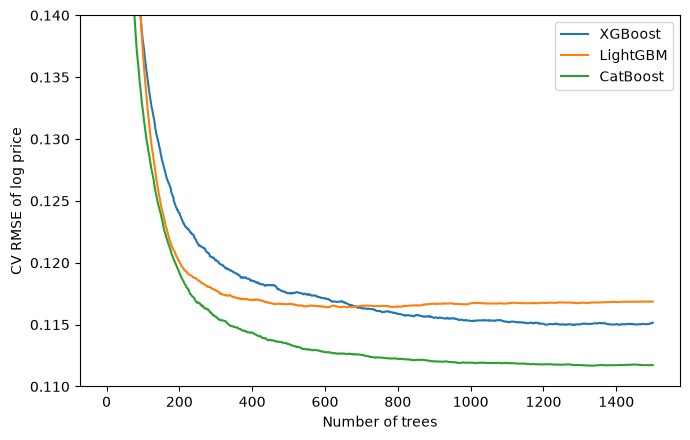

In [3]:
N_TREES = {"XGBoost": 1500, "LightGBM": 1500, "CatBoost": 1500}
RATES = {"XGBoost": 0.05, "LightGBM": 0.03, "CatBoost": 0.05}
SPACES = {
    "XGBoost": {"max_depth": [2, 3, 4, 5], "min_child_weight": [1, 3, 5], "subsample": [0.6, 0.8, 1.0], "colsample_bytree": [0.3, 0.5, 0.8], "reg_lambda": [0.1, 1, 5, 20], "gamma": [0, 0.001, 0.005]},
    "LightGBM": {"num_leaves": [4, 8, 16, 31], "min_child_samples": [5, 10, 20, 30], "subsample": [0.6, 0.8, 1.0], "colsample_bytree": [0.3, 0.5, 0.8], "reg_lambda": [0, 1, 5, 20], "min_split_gain": [0, 0.001, 0.005]},
    "CatBoost": {"depth": [4, 5, 6, 7], "l2_leaf_reg": [1, 3, 10, 30], "subsample": [0.6, 0.8, 1.0], "rsm": [0.3, 0.5, 0.8]},
}
N_SETTINGS = {"XGBoost": 24, "LightGBM": 24, "CatBoost": 12}


def make_model(library, config, n_trees):
    if library == "XGBoost":
        return XGBRegressor(n_estimators=n_trees, learning_rate=RATES[library], n_jobs=-1, random_state=0, eval_metric="rmse", **config)
    if library == "LightGBM":
        return LGBMRegressor(n_estimators=n_trees, learning_rate=RATES[library], subsample_freq=1, importance_type="gain", n_jobs=-1, random_state=0, verbose=-1, **config)
    return CatBoostRegressor(iterations=n_trees, learning_rate=RATES[library], bootstrap_type="Bernoulli", thread_count=-1, random_seed=0, verbose=0, use_best_model=False, allow_writing_files=False, **config)


def validation_curve(library, config, X_fit, y_fit, X_val, y_val):
    # The validation RMSE after each tree.
    model = make_model(library, config, N_TREES[library])
    if library == "XGBoost":
        model.fit(X_fit, y_fit, eval_set=[(X_val, y_val)], verbose=False)
        return np.array(model.evals_result()["validation_0"]["rmse"])
    if library == "LightGBM":
        model.fit(X_fit, y_fit, eval_X=X_val, eval_y=y_val, eval_metric="rmse")
        return np.array(model.evals_result_["valid_0"]["rmse"])
    model.fit(X_fit, y_fit, eval_set=(X_val, y_val))
    return np.array(model.get_evals_result()["validation"]["RMSE"])


rng = np.random.default_rng(0)
search, curves = {}, {}
for library, space in SPACES.items():
    rows = []
    for _ in range(N_SETTINGS[library]):
        config = {name: values[rng.integers(len(values))] for name, values in space.items()}
        stages = np.array([validation_curve(library, config, *data) for data in fold_data]) ** 2
        average = np.sqrt(weights @ stages)
        rows.append({**config, "Trees": int(average.argmin()) + 1, "CV RMSE": average.min()})
        curves[(library, len(rows) - 1)] = (config, stages)
    search[library] = pd.DataFrame(rows).sort_values("CV RMSE").reset_index(drop=True)

best, best_trees, best_cv, fold_best = {}, {}, {}, {}
for library, table in search.items():
    # The setting with the lowest cross-validated error at its best number of trees.
    keys = [key for key in curves if key[0] == library]
    scores = {key: np.sqrt(weights @ curves[key][1]).min() for key in keys}
    config, stages = curves[min(scores, key=scores.get)]
    average = np.sqrt(weights @ stages)
    best[library], best_trees[library], best_cv[library] = config, int(average.argmin()) + 1, float(average.min())
    fold_best[library] = np.sqrt(stages[:, best_trees[library] - 1])
    print(f"{library}: the best of {len(table)} settings")
    display(table.head(5).round(4))
print(pd.DataFrame({library: {"CV RMSE": best_cv[library], "Trees": best_trees[library], "Lowest fold": fold_best[library].min(), "Highest fold": fold_best[library].max(), "Default CV RMSE": baseline[library][0]} for library in search}).T.round(4).to_string())
print("Folds at the best settings:", {library: np.round(values, 4).tolist() for library, values in fold_best.items()})

# The cross-validated error against the number of trees, at the best settings.
plt.figure(figsize=(7, 4.5))
for library in search:
    stages = next(s for (lib, i), (config, s) in curves.items() if lib == library and config == best[library])
    plt.plot(np.arange(1, N_TREES[library] + 1), np.sqrt(weights @ stages), label=library)
plt.ylim(0.11, 0.14)
plt.xlabel("Number of trees")
plt.ylabel("CV RMSE of log price")
plt.legend()
plt.tight_layout()
plt.show()

##### Findings:
- The best cross-validated RMSE is 0.1117 for CatBoost, 0.1150 for XGBoost and 0.1164 for LightGBM. Tuning gains 0.0206 for XGBoost, 0.0098 for LightGBM and 0.0016 for CatBoost, so the three end up much closer than with the defaults, and CatBoost is level with the lasso (0.1115).
- The best settings are XGBoost with trees of depth 2, 1 house per leaf, 0.8 of the houses and columns, a `reg_lambda` of 1, a `gamma` of 0.005 and 1,285 trees. LightGBM with 8 leaves, at least 10 houses per leaf, 0.8 of the houses, 0.5 of the columns, no `reg_lambda`, a `min_split_gain` of 0.005 and 608 trees. CatBoost with a depth of 5, an `l2_leaf_reg` of 3, 0.8 of the houses, 0.5 of the columns and 1,333 trees.
- Small trees are best. Depth 2 gives the best XGBoost settings in four of the top five, all five of the best LightGBM settings have 8 leaves, and CatBoost does best at a depth of 4 or 5. Each tree is a weak learner, and many of them are summed.
- The best settings of XGBoost are within 0.0006 of each other, so many of them are equivalent. The best number of trees is below the 1,500 we fit for each, but several of the other CatBoost settings use 1,478 to 1,498, so they might improve with more trees.
- CatBoost is lowest in all five folds. Fold 3 is the hardest for all three libraries (0.1394, 0.1471 and 0.1379), as it was for the linear models and the forest.

## 5. The Fitted Models
We refit each library on all the train houses at its best settings and number of trees, and look at how the error on unseen houses compares with the error on the fitting houses. The importance of a column is the share of the total gain of the splits on it, from each library. We ask:
- How large is the gap between the error on the fitting houses and the cross-validated error?
- Which columns matter most, and do the libraries agree?
- How do the predictions treat the extrapolated Id 2550?

In [4]:
models = {library: make_model(library, best[library], best_trees[library]).fit(X, y) for library in search}
summary = pd.DataFrame(
    {
        "In-sample RMSE": {library: np.sqrt(np.mean((y - model.predict(X)) ** 2)) for library, model in models.items()},
        "CV RMSE": best_cv,
    }
)
summary["Gap"] = summary["CV RMSE"] - summary["In-sample RMSE"]
display(summary.round(4))

# The importance of each column, as a share of the total, for each library.
importance = pd.DataFrame({library: pd.Series(model.feature_importances_ if library != "CatBoost" else model.get_feature_importance(), index=features.columns) for library, model in models.items()})
importance = importance / importance.sum()
display(importance.loc[importance.mean(axis=1).sort_values(ascending=False).head(8).index].round(3))

# The predicted prices of the test houses.
predicted = pd.DataFrame({library: np.exp(model.predict(X_test)) for library, model in models.items()}, index=test_features.index)
display(pd.DataFrame({"Lowest": predicted.min(), "Median": predicted.median(), "Highest": predicted.max(), "Id 2550": predicted.loc[2550]}).round(0))
print(f"Highest train price: {np.exp(y).max():,.0f}")
print("Correlation of the predicted log prices:")
display(np.log(predicted).corr().round(4))

,In-sample RMSE,CV RMSE,Gap
XGBoost,0.0625,0.1150,0.0524
LightGBM,0.0686,0.1164,0.0478
CatBoost,0.0354,0.1117,0.0762


,XGBoost,LightGBM,CatBoost
TotalSF,0.064,0.287,0.231
OverallQual,0.109,0.195,0.134
ExterQual,0.148,0.039,0.040
GarageCars,0.096,0.040,0.018
GrLivArea,0.004,0.090,0.041
GarageFinish,0.110,0.010,0.010
HouseAge,0.011,0.046,0.054
TotalBathrooms,0.039,0.039,0.027


,Lowest,Median,Highest,Id 2550
XGBoost,34028.0,157109.0,638753.0,638753.0
LightGBM,42672.0,156770.0,702601.0,702601.0
CatBoost,35843.0,156985.0,669809.0,669809.0


Highest train price: 755,000
Correlation of the predicted log prices:


,XGBoost,LightGBM,CatBoost
XGBoost,1.0000,0.9942,0.9952
LightGBM,0.9942,1.0000,0.9950
CatBoost,0.9952,0.9950,1.0000


##### Findings:
- The in-sample RMSE is 0.0625 for XGBoost, 0.0686 for LightGBM and 0.0354 for CatBoost, against 0.1150, 0.1164 and 0.1117 cross-validated. CatBoost fits the train houses the closest, and still has the lowest error on unseen houses, so the in-sample error is not a guide to which will do best.
- `TotalSF` and `OverallQual` are among the most important columns in all three. LightGBM gives `TotalSF` the largest share (0.287), then CatBoost (0.231) and XGBoost (0.064). XGBoost spreads its importance over `ExterQual` (0.148), `GarageFinish` (0.110), `OverallQual` (0.109) and `GarageCars` (0.096), where the other two use the size more.
- The libraries disagree on how to share the size between `TotalSF` and `GrLivArea`, which overlap. `GrLivArea` has a share of 0.004 in XGBoost, 0.090 in LightGBM and 0.041 in CatBoost.
- The prediction for Id 2550 is 638,753 for XGBoost, 702,601 for LightGBM and 669,809 for CatBoost. All three are below the highest train price (755,000), so the trees do not extrapolate, but they are higher than the forest (568,000) and lower than the lasso (731,000).
- The predicted log prices of the three models have a correlation of 0.994 to 0.995, so they are very similar, and averaging them would change little.

## 6. Submission
Each model predicts the log price of the test houses, and the prediction is turned back into a price with the exponential, as in the other notebooks. We save all three, as `xgboost_v01.csv`, `lightgbm_v01.csv` and `catboost_v01.csv`, with `save_submission`, which checks each against the sample file.

In [5]:
for library, name in {"XGBoost": "xgboost", "LightGBM": "lightgbm", "CatBoost": "catboost"}.items():
    print("Saved:", save_submission(test_features.index, predicted[library].to_numpy(), name, 1))

Saved: ../submissions/xgboost_v01.csv
Saved: ../submissions/lightgbm_v01.csv
Saved: ../submissions/catboost_v01.csv


## 7. Outliers and New Columns
The models so far drop the two outlier houses (Ids 1299 and 524), as the linear notebooks did. For a linear model they distort every coefficient, but a tree only gives them their own leaves, and they are the only train houses of the same kind as the test house Id 2550: new houses with a partial sale, an `OverallQual` of 10 and a very large area. So version 2 keeps them in training. It is built for CatBoost only, the best library of section 4. The validation houses stay the same, without the two outliers, so the errors are comparable with section 4, and the cleaning statistics still come from train without them.

We also add columns that trees cannot form by themselves, with `add_tree_features` in `src/engineering.py`:
- A quality score, the mean of six quality ratings, and the products of `OverallQual` with `TotalSF`, `GrLivArea` and `OverallCond`.
- The ratio of living area to lot area, the size relative to the median of the neighbourhood, and the total porch area.
- Flags for a new and for a remodelled house, and the date of sale as a number.
- The smoothed mean log price of the neighbourhood, and an expected log price: the log of `TotalSF` plus the neighbourhood's mean log price per square foot. For the fitting houses both come from the other folds, so a house's own price is never used.

We first compare at the best CatBoost settings of section 4. We ask:
- What does keeping the outliers cost on the typical houses, and what does it do to the prediction for Id 2550?
- Do the new columns help?

In [6]:
from src.engineering import add_tree_features


def make_features_v2(fit_raw, df_raw, extra):
    # Keep the outliers in the fitting houses. The houses to predict never include them.
    fit_clean, df_clean = clean(fit_raw, fit_raw, drop_outliers=False), clean(df_raw, fit_raw)
    fit_features, df_features = engineer(fit_clean, fit_clean), engineer(df_clean, fit_clean)
    if extra:
        fit_features, df_features = add_tree_features(fit_features, fit_clean, fit_features, fit_clean), add_tree_features(df_features, df_clean, fit_features, fit_clean)
    return fit_clean, df_clean, fit_features, df_features


def fold_data_for(extra):
    data = []
    for fit_index, validation_index in folds.split(train):
        fit_clean, validation_clean, fit_features, validation_features = make_features_v2(train.iloc[fit_index], train.iloc[validation_index], extra)
        data.append((fit_features.to_numpy(dtype=float), np.log(fit_clean["SalePrice"]).to_numpy(), validation_features.to_numpy(dtype=float), np.log(validation_clean["SalePrice"]).to_numpy()))
    return data


def cv_at(library, config, n_trees, data):
    mse = np.array([np.mean((y_val - make_model(library, config, n_trees).fit(X_fit, y_fit).predict(X_val)) ** 2) for X_fit, y_fit, X_val, y_val in data])
    return np.sqrt(weights @ mse)


kept_data, extra_data = fold_data_for(False), fold_data_for(True)
fit_clean_kept, _, features_kept, test_features_kept = make_features_v2(train, test, False)
fit_clean_v2, _, features_v2, test_features_v2 = make_features_v2(train, test, True)
position = list(test_features_v2.index).index(2550)
print("Train houses and columns, version 2:", features_v2.shape, ", test:", test_features_v2.shape, ", same columns:", list(features_v2.columns) == list(test_features_v2.columns))

comparison = {}
for library in ["CatBoost"]:
    comparison[library] = {
        "CV, dropped (section 4)": best_cv[library],
        "CV, kept": cv_at(library, best[library], best_trees[library], kept_data),
        "CV, kept, new columns": cv_at(library, best[library], best_trees[library], extra_data),
        "Id 2550, dropped": predicted.loc[2550, library],
    }
    for label, (fit_features, test_fit_features, fit_clean_set) in {"Id 2550, kept": (features_kept, test_features_kept, fit_clean_kept), "Id 2550, kept, new columns": (features_v2, test_features_v2, fit_clean_v2)}.items():
        model = make_model(library, best[library], best_trees[library]).fit(fit_features.to_numpy(dtype=float), np.log(fit_clean_set["SalePrice"]).to_numpy())
        comparison[library][label] = float(np.exp(model.predict(test_fit_features.to_numpy(dtype=float))[position]))
comparison = pd.DataFrame(comparison).T
display(comparison[[column for column in comparison.columns if column.startswith("CV")]].round(4))
display(comparison[[column for column in comparison.columns if column.startswith("Id")]].round(0))

Train houses and columns, version 2: (1460, 189) , test: (1459, 189) , same columns: True


,"CV, dropped (section 4)","CV, kept","CV, kept, new columns"
CatBoost,0.1117,0.1141,0.1134


,"Id 2550, dropped","Id 2550, kept","Id 2550, kept, new columns"
CatBoost,669809.0,232357.0,211597.0


##### Findings:
- Keeping the outliers costs a little on the typical houses at the CatBoost settings of section 4. The cross-validated RMSE rises from 0.1117 to 0.1141.
- The new columns win back part of it, to 0.1134.
- The prediction for Id 2550 changes completely. With the outliers dropped it is 669,809. With them kept it is 232,357, and with the new columns as well 211,597. The two outliers are the only houses that tell the model what a house like this sells for.

## 8. Tuning Version 2
We tune CatBoost again, with the outliers kept and the new columns. The best settings of section 4 are included as one of the candidates, so the search cannot do worse than them. We widen the search: a depth of 4 to 8, an `l2_leaf_reg` of 1, 3, 5, 10 or 30, a `subsample` of 0.6, 0.7, 0.8 or 1, an `rsm` of 0.3, 0.5 or 0.8, and `random_strength`, which adds noise to the scores of the candidate splits so that the trees differ more, of 0.5, 1, 2 or 5. CatBoost gets 2,000 trees and 16 random settings, drawn once from these lists and written out below, so that the search is the same whichever libraries are tuned. We ask:
- Which settings are best now, and how much lower is the error than in section 4?
- Is the best number of trees at the limit?

In [7]:
N_TREES["CatBoost"] = 2000

# The best settings of section 4, then the 16 random settings.
CANDIDATES_V2 = [
    best["CatBoost"],
    {"depth": 8, "l2_leaf_reg": 5, "subsample": 0.7, "rsm": 0.8, "random_strength": 5},
    {"depth": 5, "l2_leaf_reg": 30, "subsample": 1.0, "rsm": 0.8, "random_strength": 2},
    {"depth": 8, "l2_leaf_reg": 1, "subsample": 0.6, "rsm": 0.8, "random_strength": 1},
    {"depth": 6, "l2_leaf_reg": 10, "subsample": 0.7, "rsm": 0.5, "random_strength": 5},
    {"depth": 8, "l2_leaf_reg": 1, "subsample": 1.0, "rsm": 0.8, "random_strength": 2},
    {"depth": 4, "l2_leaf_reg": 30, "subsample": 0.7, "rsm": 0.8, "random_strength": 0.5},
    {"depth": 4, "l2_leaf_reg": 30, "subsample": 0.8, "rsm": 0.5, "random_strength": 5},
    {"depth": 8, "l2_leaf_reg": 1, "subsample": 0.8, "rsm": 0.8, "random_strength": 2},
    {"depth": 7, "l2_leaf_reg": 5, "subsample": 0.8, "rsm": 0.3, "random_strength": 0.5},
    {"depth": 5, "l2_leaf_reg": 10, "subsample": 1.0, "rsm": 0.8, "random_strength": 0.5},
    {"depth": 4, "l2_leaf_reg": 30, "subsample": 0.8, "rsm": 0.8, "random_strength": 5},
    {"depth": 5, "l2_leaf_reg": 30, "subsample": 0.8, "rsm": 0.5, "random_strength": 1},
    {"depth": 5, "l2_leaf_reg": 3, "subsample": 0.8, "rsm": 0.5, "random_strength": 0.5},
    {"depth": 4, "l2_leaf_reg": 1, "subsample": 0.7, "rsm": 0.5, "random_strength": 5},
    {"depth": 7, "l2_leaf_reg": 3, "subsample": 0.8, "rsm": 0.8, "random_strength": 5},
    {"depth": 6, "l2_leaf_reg": 10, "subsample": 0.6, "rsm": 0.5, "random_strength": 5},
]

search_v2, best_v2, best_trees_v2, best_cv_v2, fold_best_v2 = {}, {}, {}, {}, {}
library = "CatBoost"
rows, all_stages = [], []
for config in CANDIDATES_V2:
    stages = np.array([validation_curve(library, config, *data) for data in extra_data]) ** 2
    average = np.sqrt(weights @ stages)
    rows.append({**config, "Trees": int(average.argmin()) + 1, "CV RMSE": average.min()})
    all_stages.append(stages)
scores = [row["CV RMSE"] for row in rows]
k = int(np.argmin(scores))
best_v2[library], best_trees_v2[library], best_cv_v2[library] = CANDIDATES_V2[k], rows[k]["Trees"], scores[k]
fold_best_v2[library] = np.sqrt(all_stages[k][:, best_trees_v2[library] - 1])
search_v2[library] = pd.DataFrame(rows).sort_values("CV RMSE").reset_index(drop=True)
print(f"{library}: the best of {len(CANDIDATES_V2)} settings, the first being the best of section 4")
display(search_v2[library].head(5).round(4))

print(pd.DataFrame({library: {"CV RMSE, section 4": best_cv[library], "CV RMSE, version 2": best_cv_v2[library], "Trees": best_trees_v2[library], "Trees fitted": N_TREES[library], "Lowest fold": fold_best_v2[library].min(), "Highest fold": fold_best_v2[library].max()} for library in search_v2}).T.round(4).to_string())
print("Best settings:", best_v2)

CatBoost: the best of 17 settings, the first being the best of section 4


,depth,l2_leaf_reg,subsample,rsm,Trees,CV RMSE,random_strength
0,4,1,0.7,0.5,1722,0.1121,5.0
1,6,10,0.7,0.5,1741,0.1123,5.0
2,4,30,0.8,0.5,1999,0.1123,5.0
3,5,30,0.8,0.5,1971,0.1125,1.0
4,4,30,0.8,0.8,1808,0.1127,5.0


          CV RMSE, section 4  CV RMSE, version 2   Trees  Trees fitted  Lowest fold  Highest fold
CatBoost              0.1117              0.1121  1722.0        2000.0       0.0966        0.1396
Best settings: {'CatBoost': {'depth': 4, 'l2_leaf_reg': 1, 'subsample': 0.7, 'rsm': 0.5, 'random_strength': 5}}


##### Findings:
- The best CatBoost settings are a depth of 4, an `l2_leaf_reg` of 1, 0.7 of the houses, 0.5 of the columns, a `random_strength` of 5 and 1,722 trees, at 0.1121.
- The tuning wins back the cost of keeping the outliers. On the typical houses, version 2 is level with section 4: 0.1121 against 0.1117.
- Four of the five best settings have the largest `random_strength`, 5, so more randomness in the splits helps.
- The best number of trees is not at the limit (1,722 of 2,000), but one of the other good settings used 1,999, so it might improve with more trees.

## 9. Seed Averaging
A boosted model depends on its random seed, through the samples of houses and columns for each tree. Averaging the predictions of CatBoost models that differ only in the seed reduces this variance without adding bias, like a small bagging of the whole model. We compare one seed with the average of three, at the best settings of section 8, with the same cross-validation. We ask:
- How much does the average of three seeds lower the error?

In [8]:
SEEDS = [0, 1, 2]


def with_seed(library, config, n_trees, seed):
    model = make_model(library, config, n_trees)
    return model.set_params(**({"random_seed": seed} if library == "CatBoost" else {"random_state": seed}))


seed_rows = {}
for library in search_v2:
    single, averaged = [], []
    for X_fit, y_fit, X_val, y_val in extra_data:
        fold_predictions = np.array([with_seed(library, best_v2[library], best_trees_v2[library], seed).fit(X_fit, y_fit).predict(X_val) for seed in SEEDS])
        single.append(np.mean((y_val - fold_predictions[0]) ** 2))
        averaged.append(np.mean((y_val - fold_predictions.mean(axis=0)) ** 2))
    seed_rows[library] = {"One seed": np.sqrt(weights @ np.array(single)), "Three seeds": np.sqrt(weights @ np.array(averaged))}
seed_table = pd.DataFrame(seed_rows).T
seed_table["Gain"] = seed_table["One seed"] - seed_table["Three seeds"]
display(seed_table.round(4))

,One seed,Three seeds,Gain
CatBoost,0.1121,0.1106,0.0015


##### Findings:
- The average of three seeds lowers the cross-validated RMSE from 0.1121 to 0.1106.
- At 0.1106 this is the lowest cross-validated error of any model so far, below the lasso (0.1115).
- The best settings use only 0.7 of the houses for each tree, so the trees depend on the seed and averaging helps.

## 10. Version 2 Model and Submission
We refit CatBoost on all the train houses, with the outliers and the new columns, at its best settings, average the predictions of three seeds, and save `catboost_v02.csv` with `save_submission`. We ask:
- How do the predictions of version 2 compare with version 1, in particular for Id 2550?
- How much does the model use the new columns?

In [9]:
X_v2, y_v2, X_test_v2 = features_v2.to_numpy(dtype=float), np.log(fit_clean_v2["SalePrice"]).to_numpy(), test_features_v2.to_numpy(dtype=float)
predicted_v2, importance_v2 = {}, {}
for library in search_v2:
    fitted = [with_seed(library, best_v2[library], best_trees_v2[library], seed).fit(X_v2, y_v2) for seed in SEEDS]
    predicted_v2[library] = np.exp(np.mean([model.predict(X_test_v2) for model in fitted], axis=0))
    shares = np.mean([model.feature_importances_ if library != "CatBoost" else model.get_feature_importance() for model in fitted], axis=0)
    importance_v2[library] = pd.Series(shares / shares.sum(), index=features_v2.columns)
predicted_v2 = pd.DataFrame(predicted_v2, index=test_features_v2.index)
display(pd.DataFrame({"Lowest": predicted_v2.min(), "Median": predicted_v2.median(), "Highest": predicted_v2.max(), "Id 2550": predicted_v2.loc[2550], "Id 2550, version 1": predicted.loc[2550, ["CatBoost"]]}).round(0))
print("Correlation of the log predictions of version 1 and version 2:", {library: round(float(np.corrcoef(np.log(predicted[library]), np.log(predicted_v2[library]))[0, 1]), 4) for library in search_v2})

# The share of the importance that goes to the new columns.
importance_v2 = pd.DataFrame(importance_v2)
new_columns = [column for column in features_v2.columns if column not in features.columns]
print("Share of the importance in the new columns:", importance_v2.loc[new_columns].sum().round(3).to_dict())
display(importance_v2.loc[new_columns].sort_values("CatBoost", ascending=False).round(3))

for library, name in {"CatBoost": "catboost"}.items():
    print("Saved:", save_submission(test_features_v2.index, predicted_v2[library].to_numpy(), name, 2))

,Lowest,Median,Highest,Id 2550,"Id 2550, version 1"
CatBoost,37496.0,156830.0,535672.0,231474.0,669809.0


Correlation of the log predictions of version 1 and version 2: {'CatBoost': 0.9944}
Share of the importance in the new columns: {'CatBoost': 0.426}


,CatBoost
QualityTimesTotalSF,0.121
ExpectedLogPrice,0.082
QualityTimesLivingArea,0.075
NeighbourhoodPrice,0.060
QualityTimesCondition,0.031
QualityScore,0.023
TotalPorchSF,0.011
RelativeSize,0.008
LivingToLotRatio,0.006
YearMonthSold,0.005


Saved: ../submissions/catboost_v02.csv


##### Findings:
- The prediction for Id 2550 is 231,474, against 669,809 in version 1. The highest test prediction is now 535,672, for another house.
- For the rest of the houses, version 2 is close to version 1: the log predictions have a correlation of 0.9944.
- The model uses the new columns heavily, with a share of the importance of 0.426. Most of it goes to `QualityTimesTotalSF` (0.121) and `ExpectedLogPrice` (0.082), then `QualityTimesLivingArea`, `NeighbourhoodPrice` and `QualityScore`. The porch total, the ratios and the flags get little, at most 0.011 each.